<a href="https://colab.research.google.com/github/RISHABH12005/Quantum-Computing/blob/main/QuDAIS%20Lab%5CQiskit_101_Hands_on_Fall_Fest_2026.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# First Step into Quantum Computing

- **Difficulty:** Beginner
- **QPU time usage:** under 1 minute (two short jobs)

Welcome, hackers! We're thrilled to have you at the workshop. The goal of this introductory hands-on session is to get you ready for your quantum journey. You will:

1. install Qiskit,
2. set up an IBM Quantum Platform account and get the **API key** and **CRN** you need to use a real quantum computer,
3. build your first quantum circuits and visualize qubit states,
4. solve two quantum state quizzes,
5. run your circuits on a simulator, and
6. run them on a real quantum computer and compare the results.

As a bonus, you can connect Qiskit to an AI coding assistant (Claude Code or OpenAI Codex) using MCP servers.

> **Before the session:** please work through sections 1 and 2 (installing Qiskit and setting up your IBM Quantum account) in advance, so that we can spend the workshop time on the quantum part.

## 1. First things first: Qiskit

### What is Qiskit?

**[Qiskit](https://www.ibm.com/quantum/qiskit)** is a high-performance software stack built to help developers and researchers harness the full power of quantum computers at utility scale and beyond. At its core is the Qiskit SDK, an open-source software development kit for working with quantum computers at the level of extended quantum circuits, operators, and primitives. The Qiskit SDK lets anyone get optimal performance from real quantum computers using their preferred computing environment.

Beyond the SDK, Qiskit also includes a suite of high-performance tools and services, such as the [IBM Quantum Compute Service (formerly Qiskit Runtime)](https://quantum.cloud.ibm.com/docs/en/api/qiskit-ibm-runtime/runtime-service), which runs optimized computations on IBM quantum computers through the cloud, using primitives that manage error mitigation. The Qiskit Transpiler Service provides state-of-the-art heuristic and AI-powered methods that boost performance for common circuit optimization tasks.

[Qiskit Functions](https://quantum.cloud.ibm.com/docs/en/guides/functions) form a catalog of IBM and third-party services that make it easy to optimize workloads and use Qiskit for industry use cases. Whether you're a quantum software developer, a quantum experimentalist, a computational scientist, or just getting started, Qiskit's modular, flexible framework lets you work at the level of abstraction that best suits your needs.

Qiskit is designed for extensibility and customization, so you can extract industry-leading performance and tackle new kinds of problems. Its high-performance code base means the Qiskit SDK works faster, uses less memory, and delivers better results than ever before. Qiskit also connects you with a vast community of users and developers who are eager to welcome you and help answer your questions. First launched in 2019, the [Qiskit Advocate program](https://www.ibm.com/quantum/blog/qiskit-advocate-program) is a global, community-centered initiative that recruits quantum computing professionals and enthusiasts from all over the world. Over the years, advocates have gone on to become recognized leaders in the quantum community. Want to be the next quantum leader? Don't hesitate to [apply here](https://airtable.com/app8koO4BZifGFhCV/pagJvJphu4PBNkuE7/form).

### Install Qiskit

First, check that you are using **Python 3.10 or later**, which the latest Qiskit requires, by running the cell below. (If you plan to try the bonus MCP section at the end, use Python 3.10–3.13.)

In [ ]:
from platform import python_version
print(python_version())

If your version is older, upgrade Python using your preferred tool. Some recommended options:

- **Windows:** the installer from [python.org](https://www.python.org/downloads/)
- **macOS:** [Homebrew](https://brew.sh/) (`brew install python`)
- **Linux:** your package manager, for example `sudo apt-get update && sudo apt-get install python3`

For a detailed guide for each operating system, see [How to update Python](https://4geeks.com/how-to/how-to-update-python-version).

Next, install Qiskit and the other packages this lab uses by running the cell below. Then verify the installation with the cell after it: if everything installed correctly, it prints your Qiskit version.

In [ ]:
# sympy is needed by array_to_latex in section 4; qiskit-ibm-runtime 0.50+ provides the primitives used in section 6
%pip install qiskit qiskit-aer "qiskit-ibm-runtime>=0.50" matplotlib pylatexenc sympy

In [ ]:
import qiskit

print(f"Qiskit version: {qiskit.__version__}")

### Troubleshooting

If the previous cell raised an error, install Qiskit in a virtual environment instead. If you had no errors, skip this cell and continue.

Two suggested ways to set up a virtual environment:

1. Using [venv](https://docs.python.org/3/library/venv.html), as explained in the [Qiskit installation guide](https://quantum.cloud.ibm.com/docs/en/guides/install-qiskit).
2. Using [conda](https://docs.conda.io/projects/conda/en/latest/user-guide/install/index.html), as explained in this [Coding with Qiskit video](https://www.youtube.com/watch?v=93-zLTppFZw&list=PLOFEBzvs-VvrgHZt3exM_NNiNKtZlHvZi&index=4).

## 2. Set up your IBM Quantum account <a id="setting-ibm-cloud"></a>

To run on a real quantum computer, you need two things: an **API key** (your entrance ticket) and a **CRN** (the address of the instance your jobs are billed to).

1. Go to [IBM Quantum Platform](https://quantum.cloud.ibm.com/).
2. Click **Sign in** at the top right.
3. **New to the platform?** On the sign-in page, click **Create an IBM Cloud account →**, create the account, then return to this page and sign in.
4. You land on your home page. In the panel on the left, next to **API key**, click **Create +**. **Copy the key straight away and keep it somewhere safe: it is shown only once.**
5. Create an instance: go to [quantum.cloud.ibm.com/instances](https://quantum.cloud.ibm.com/instances) and click **Create instance +**. **Choose the Open plan**: it's free, with 10 minutes of QPU time every 28 days. That is enough for this lab, but it is shared across everything you run, so avoid accidental re-runs of the hardware cells.
6. Once created, the instance appears in the **Instances** panel on the left of your home page and in the table on the Instances page. Click the **CRN** copy icon to copy it. (Refresh the page if the new instance doesn't appear yet.)
7. Paste the API key from step 4 and the CRN from step 6 into the two placeholders in the next code cell.

See the [Cloud setup guide](https://quantum.cloud.ibm.com/docs/en/guides/cloud-setup) for more detail.

<div class="alert alert-block alert-warning">

⚠️ **Note:** Treat your API key like a password: *"Your token is confidential. Do not share your token in public code."* You only need to run the next cell **once**. After that, the key is stored on your own machine, and a plain `QiskitRuntimeService()` picks it up automatically. See the [Save your access credentials](https://quantum.cloud.ibm.com/docs/en/guides/save-credentials) guide for advice on secure versus untrusted environments.

If your university is part of the IBM Quantum partner network, use your institution's email address for your IBM ID to receive the partner benefits.
</div>

In [ ]:
from qiskit_ibm_runtime import QiskitRuntimeService

# Paste the two values you copied in step 4 and step 6 above
your_api_key = "deleteThisAndPasteYourAPIKeyHere"
your_crn     = "deleteThisAndPasteYourCRNHere"

if not your_api_key or not your_crn or "deleteThis" in your_api_key + your_crn:
    print("Paste your API key and CRN into the two lines above, then run this cell again.")
else:
    QiskitRuntimeService.save_account(
        channel="ibm_quantum_platform",  # current channel ("ibm_cloud" is being deprecated)
        token=your_api_key,
        instance=your_crn,
        name="fallfest",                 # labels this account, keeps it separate from any others
        set_as_default=True,             # a bare QiskitRuntimeService() will now use it
        overwrite=True,                  # lets you re-run this cell after a typo
    )
    print("Account saved. You don't need to run this cell again,")
    print("and you can now delete your API key from it before sharing this notebook.")

In [ ]:
# Check that the account has been saved properly
service = QiskitRuntimeService()
account = service.active_account()
print("Channel :", account.get("channel"))
print("Instance:", account.get("instance"))
print("\nSigned in successfully.")

In [ ]:
# See the backends (QPUs) you can use
service.backends()

## 3. Your first quantum circuit

### Quantum circuits

The fundamental unit of Qiskit is the **quantum circuit**: a series of instructions that a quantum computer uses to work with quantum bits of information, also known as **qubits**. Qubits have special properties that let quantum computers approach problems differently from your laptop or phone. Qiskit is advancing rapidly as a technology. You can still design your quantum circuits by hand and decide how you want them to run (and there are plenty of good reasons to do so), but IBM Quantum also provides tools that simplify the process. For the sake of learning, we will design some very simple circuits, run them on a simulator, and then on a real quantum computer.

We're breezing through this overview because, honestly, we could spend hours just explaining the basics of quantum information and computation. In fact, IBM Quantum has done this already, producing a [written course](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/single-systems/introduction) and a series of [video lectures](https://www.youtube.com/playlist?list=PLOFEBzvs-VvqKKMXX4vbi4EB1uaErFMSO) devoted to the topic. If you need a refresher, check them out!

In [ ]:
from qiskit import QuantumCircuit
from qiskit.quantum_info import SparsePauliOp, Statevector
from qiskit.visualization import plot_bloch_multivector, plot_state_qsphere, array_to_latex, plot_histogram
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_aer.primitives import SamplerV2 as Sampler_Aer, EstimatorV2 as Estimator_Aer
from qiskit_ibm_runtime import QiskitRuntimeService
from qiskit_ibm_runtime.executor_sampler import Sampler        # requires qiskit-ibm-runtime 0.50 or later
from qiskit_ibm_runtime.executor_estimator import Estimator

import matplotlib.pyplot as plt

### Basic operations on qubits and measurements

#### Writing down single-qubit states

Let's start by looking at a single qubit. A classical bit can only take the values 0 and 1. A quantum bit, or **qubit**, can be in the states $\vert0\rangle$ and $\vert1\rangle$, as well as in a linear combination of the two. This property is known as **superposition**, and it lets us write the most general state of a qubit as:

$$\vert\psi\rangle = \sqrt{1-p}\,\vert0\rangle + e^{i \phi} \sqrt{p}\,\vert1\rangle$$

If we measure this qubit, we get the result $1$ with probability $p$ and the result $0$ with probability $1-p$. The total probability is $1$, meaning that we will always measure either $0$ or $1$; no other outcome exists.

In addition to $p$, you might have noticed another parameter above. The variable $\phi$ is the relative quantum phase between the two states $\vert0\rangle$ and $\vert1\rangle$. As we will discover later, this relative phase is very important. For now, it's enough to note that the quantum phase is what enables interference between quantum states, which is what makes quantum algorithms work.

#### Visualizing quantum states

A single qubit's state has just two free parameters, the probability $p$ and the phase $\phi$, so we can draw it as a point on the surface of a sphere. This is the **Bloch sphere**, the most intuitive picture of one qubit:

- the **north pole** is $\vert0\rangle$ and the **south pole** is $\vert1\rangle$;
- anywhere on the **equator** is an equal superposition, with a 50/50 chance of measuring 0 or 1;
- going *around* the equator changes the phase $\phi$ without changing any measurement probability.

To get a feel for it, open [bloch.kherb.io](https://bloch.kherb.io/) in a new browser tab: an interactive Bloch sphere that animates the rotation as each gate is applied (no install or login needed). Try **H**, then **H** again, then **Z** before and after an **H**.

Let's see it in Qiskit. Every qubit starts in $\vert0\rangle$, pointing straight up.

In [ ]:
# visualize |0> on the Bloch sphere
qc = QuantumCircuit(1)
plot_bloch_multivector(qc)

Applying a **Hadamard gate** ($H$) tips it onto the equator, giving the equal superposition $\vert+\rangle = \frac{1}{\sqrt{2}}(\vert0\rangle + \vert1\rangle)$:

In [ ]:
# apply H: |0> -> |+>
qc.h(0)
plot_bloch_multivector(qc)

The Bloch sphere is wonderful, but it only works for **one** qubit. Two qubits need four amplitudes, three need eight, and no sphere can hold them. So from here on we use the **qsphere** instead: it keeps the same north-pole/south-pole convention for $\vert0\rangle$ and $\vert1\rangle$, but every basis state gets its own point, with the **size** of the blob showing its probability and the **color** showing its phase.

In [ ]:
# visualize |0> on the qsphere
qc = QuantumCircuit(1)
plot_state_qsphere(qc)

It should be no surprise that the superposition state with quantum phase $\phi = 0$ and probability $p = 1/2$ (an equal chance of measuring 0 or 1) appears on the qsphere below as two points. Notice also that the circles are smaller than the single circle for $\vert0\rangle$ above. This is because the size of each circle is proportional to the probability of measuring that state, which is now halved.

In [ ]:
# visualize |+> = (|0> + |1>)/sqrt(2)
qc.h(0)
plot_state_qsphere(qc)

For superposition states with a non-zero quantum phase, the qsphere shows the phase by changing the color of the corresponding blob. For example, the state with $\phi = 90^\circ$ and probability $p = 1/2$ is shown on the qsphere below.

In [ ]:
# the S gate adds a phase of 90 degrees
qc.s(0)
plot_state_qsphere(qc)

### Manipulating qubits

Qubits are manipulated by applying quantum gates. Let's go through an overview of the gates we will use in the following exercises.

First, let's describe how we can change the value of $p$ in our general quantum state. To do this, we use two gates:

1. **$X$ gate**: flips between the two states $\vert0\rangle$ and $\vert1\rangle$. This is the same operation as the classical NOT gate, so the $X$ gate is sometimes called a bit-flip or NOT gate. Mathematically, the $X$ gate changes $p$ to $1-p$; in particular, from 0 to 1 and vice versa.

2. **$H$ gate**: takes the state $\vert0\rangle$ to the state $\frac{1}{\sqrt{2}}\left(\vert0\rangle + \vert1\rangle\right)$, also known as $\vert+\rangle$. Mathematically, this means going from $p=0, \phi=0$ to $p=1/2, \phi=0$. Because the final state of the qubit is a superposition of $\vert0\rangle$ and $\vert1\rangle$, the Hadamard gate is a truly quantum operation.

Notice that both gates change the value of $p$, but not $\phi$. Fortunately, it's easy to visualize the action of these gates in the figure below.

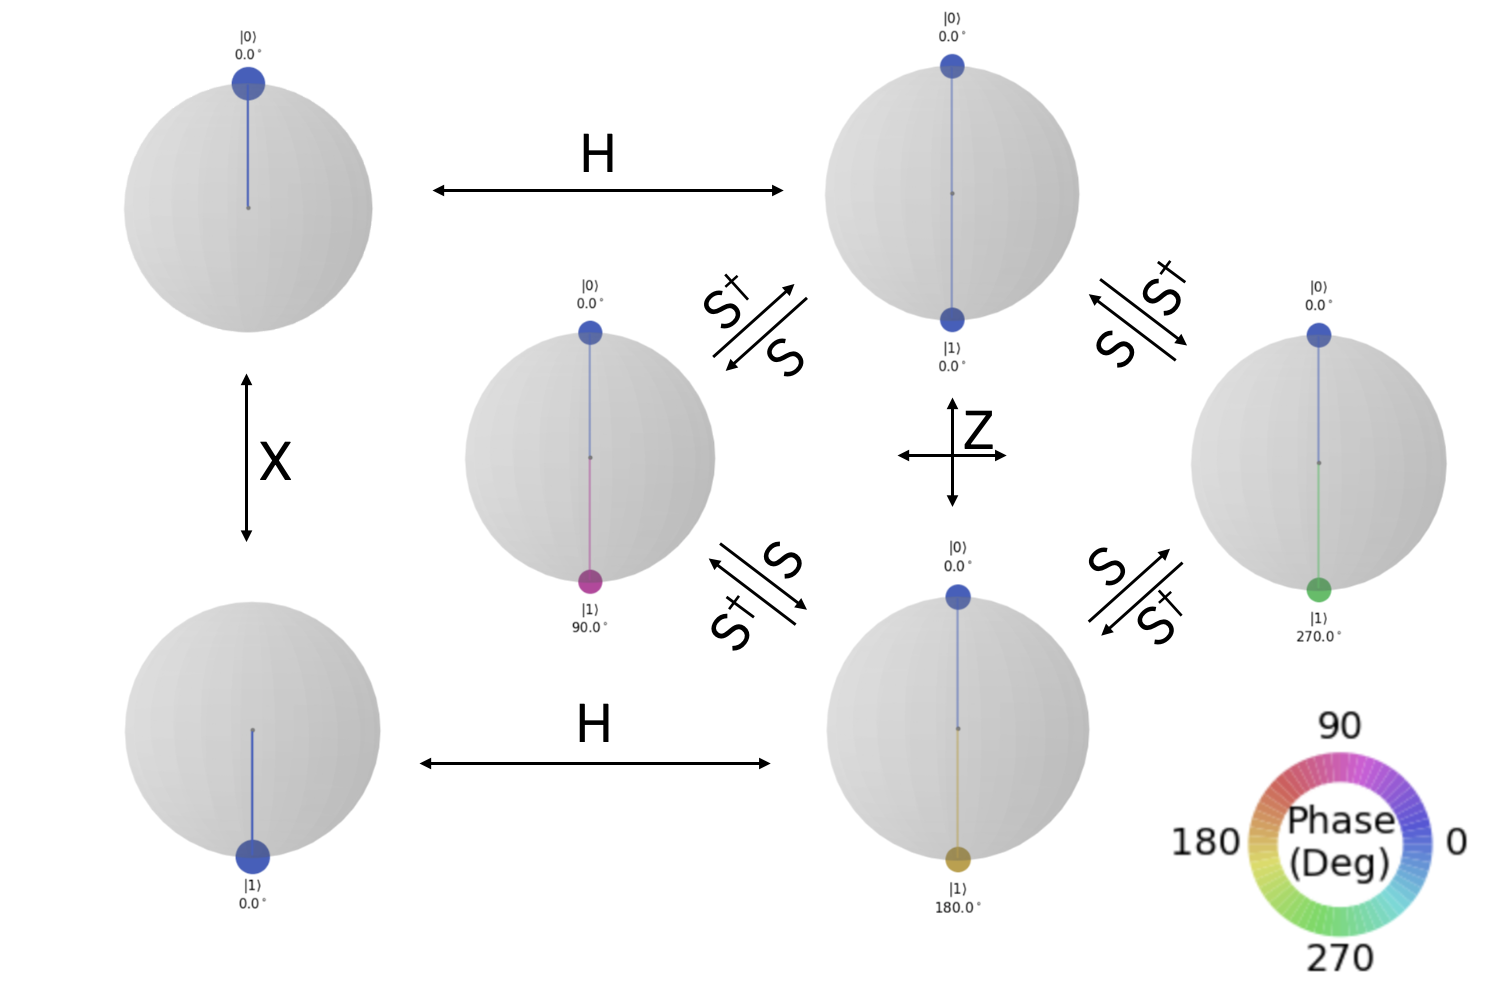

Once we have the state $\vert+\rangle$, we can change the quantum phase by applying other gates. For example, the $S$ gate adds a phase of $90$ degrees to $\phi$, while the $Z$ gate adds a phase of $180$ degrees. To subtract a phase of $90$ degrees, we can apply the $S^\dagger$ gate, read as "S-dagger" and written `sdg` in Qiskit. Finally, the $Y$ gate applies a sequence of $Z$ and $X$ gates.

Experiment with the gates $X$, $Y$, $Z$, $H$, $S$, and $S^\dagger$ to get used to the different operations and how they affect the state of a qubit. To do so, open [IBM Quantum Composer](https://quantum.cloud.ibm.com/composer), drag a gate onto a qubit (in the first examples, the only qubit is qubit 0), and watch how the state and its description change with each gate. Composer also shows you the Qiskit code that creates the corresponding circuit.

To learn more about describing quantum states, Pauli operators, and other single-qubit gates, see the [Quantum information](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/single-systems/quantum-information) lesson on single systems in John Watrous's [Basics of Quantum Information](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information) course.

### Note: qubit ordering convention (little-endian)

Qiskit uses **little-endian** ordering: qubit 0 is the **rightmost** position in ket notation.

$$\vert q_{n-1}\, \cdots\, q_1\, q_0\rangle \quad \Longleftarrow \quad \text{qubit 0 is rightmost}$$

We follow this convention throughout this notebook. For example, a 2-qubit register with an ancilla on $q_0$ and data on $q_1$ is written $\vert\text{data}\rangle\vert\text{ancilla}\rangle$, **not** $\vert\text{ancilla}\rangle\vert\text{data}\rangle$.

In circuit diagrams, Qiskit draws $q_0$ at the **top**.

## 4. Quantum quiz with multi-qubit gates

Great job! Now that you understand single-qubit gates, let's look at gates that act on multiple qubits. In this section, you will solve two quantum state quizzes by combining single-qubit and multi-qubit gates. The basic two-qubit gates are:

    qc.cx(c,t)       # controlled-X (= CNOT) gate with control qubit c and target qubit t
    qc.cz(c,t)       # controlled-Z gate with control qubit c and target qubit t
    qc.swap(a,b)     # SWAP gate that swaps the states of qubit a and qubit b

To read more about the different multi-qubit gates and how they relate, see the [Quantum information](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/multiple-systems/quantum-information) lesson on multiple systems in John Watrous's *Basics of Quantum Information* course.

For two qubits, a general state has the form $a|00\rangle + b |01\rangle + c |10\rangle + d|11\rangle$, where $a$, $b$, $c$, and $d$ are complex numbers whose absolute values squared give the probability of measuring the respective state; for example, $|a|^2$ is the probability of measuring 0 on both qubits. This means the qsphere can now show up to four points.

We start with the canonical two-qubit gate, the controlled-NOT (also called CNOT or CX) gate. As with all controlled two-qubit gates, one qubit is the "control" and the other is the "target". If the control qubit is in state $|0\rangle$, the identity gate $I$ is applied to the target; that is, nothing happens. If the control qubit is in state $|1\rangle$, an $X$ gate is applied to the target. So when both qubits are in one of the classical states, $|0\rangle$ or $|1\rangle$, the CNOT gate acts just like a classical gate.

This changes dramatically when we first apply a Hadamard gate to the control qubit, putting it in the superposition state $|+\rangle$. A CNOT gate acting on this non-classical input can produce highly entangled states of the control and target qubits. If the target qubit is initially in the $|0\rangle$ state, the resulting state is denoted $|\Phi^+\rangle$ and is one of the so-called [Bell states](https://quantum.cloud.ibm.com/learning/en/courses/basics-of-quantum-information/multiple-systems/quantum-information#bell-states).

#### i) Construct the Bell state $|\Phi^+\rangle = \frac{1}{\sqrt{2}}\left(|00\rangle + |11\rangle\right)$.

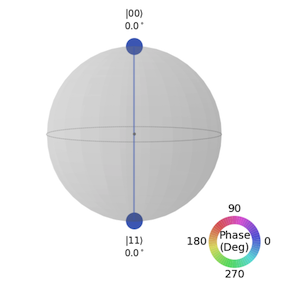


For this state, we measure "00" with probability $\frac{1}{2}$ and "11" with probability $\frac{1}{2}$, so the outcomes of the two qubits are perfectly correlated.

In [ ]:
def create_circuit1():
    qc = QuantumCircuit(2)
    #
    #
    # FILL YOUR CODE IN HERE
    #
    #
    return qc

qc1 = create_circuit1()
state = Statevector(qc1)    # the final state after running the circuit
display(array_to_latex(state))
display(plot_state_qsphere(state, show_state_labels=True, show_state_phases=True, use_degrees=True))
qc1.draw(output="mpl")      # draw the circuit

Next, try to create a state of perfectly anti-correlated qubits. Note the minus sign, which indicates the relative phase between the two states.

#### ii) Construct the Bell state $\vert\Psi^-\rangle = \frac{1}{\sqrt{2}}\left(\vert01\rangle - \vert10\rangle\right)$.

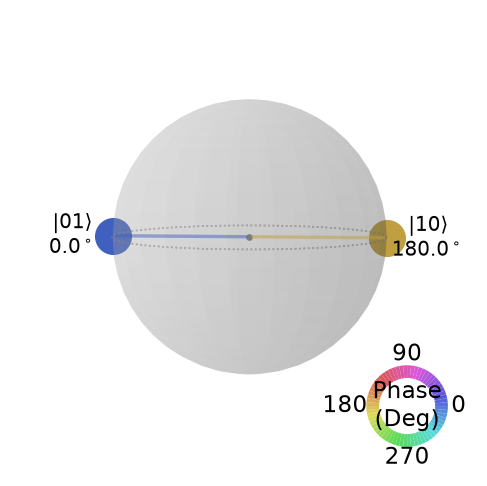

In [ ]:
def create_circuit2():
    qc = QuantumCircuit(2)
    #
    #
    # FILL YOUR CODE IN HERE
    #
    #
    return qc

qc2 = create_circuit2()
state = Statevector(qc2)    # the final state after running the circuit
display(array_to_latex(state))
display(plot_state_qsphere(state, show_state_labels=True, show_state_phases=True, use_degrees=True))
qc2.draw(output="mpl")      # draw the circuit

## 5. Run your circuit on a simulator

Now that we know how to build quantum circuits, it's time for the most exciting part: running them and seeing the output! We'll start on a **local simulator**, which runs your circuit exactly as written, with no hardware noise. Its answer is the ideal result that we'll compare the real QPU against in section 6.

We will use the two [Qiskit primitives](https://quantum.cloud.ibm.com/docs/en/guides/primitives):

1. **Sampler** samples the output register from the execution of one or more quantum circuits. Its output is the counts of the per-shot measurement outcomes.
2. **Estimator** computes the expectation values of one or more observables with respect to the states prepared by the quantum circuits. Its output is the expectation values together with their standard errors.

Qiskit offers these primitives from more than one provider, and they all share the same interface. In this section we use the **Aer** versions (`Sampler_Aer` and `Estimator_Aer` from `qiskit_aer.primitives`), which simulate the circuit locally on your laptop: free, instant, and noise-free. In section 6 we'll switch to the **IBM Runtime** versions, which send the same circuits to a real quantum computer.

First, let's build the Bell state $\vert\Phi^+\rangle$ in two versions: one with measurements for the Sampler, and one without for the Estimator, which adds the measurements it needs by itself.

In [ ]:
# Bell state |Phi+> without measurements, for the Estimator
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

# a copy with measurements, for the Sampler
bell_meas = bell.measure_all(inplace=False)
bell_meas.draw("mpl")

### Sampler

The Sampler runs the measured circuit many times (**shots**) and counts how often each outcome appears.

In [ ]:
sampler = Sampler_Aer()
SHOTS = 10_000

pub = (bell_meas,)
result = sampler.run([pub], shots=SHOTS).result()
counts_sim = result[0].data.meas.get_counts()

plot_histogram(counts_sim)

You should see only `00` and `11`, in roughly equal numbers. The split won't be exactly 5,000/5,000: with a finite number of shots, the counts fluctuate slightly around the ideal values. This is called *shot noise*, and it's the same reason 10,000 coin flips rarely give exactly 5,000 heads. What the simulator will **never** give you is `01` or `10`, because the ideal state $\vert\Phi^+\rangle$ can't produce them.

### Estimator

The Sampler tells us *how often* each outcome appears. The **Estimator** answers a different question: what is the average (expectation) value of an observable? Below we measure six two-qubit Pauli observables on the Bell state.

In [ ]:
estimator = Estimator_Aer()
PRECISION = 0.01    # target standard error of each expectation value

labels = ["IX", "IZ", "XI", "ZI", "ZZ", "XX"]
observables = [SparsePauliOp(label) for label in labels]

pub = (bell, observables)
result = estimator.run([pub], precision=PRECISION).result()
evs = result[0].data.evs     # expectation values

plt.bar(labels, evs)
plt.axhline(0, color="k", lw=0.8)
plt.ylim(-1.1, 1.1)
plt.xlabel("Observable")
plt.ylabel("Expectation value")
plt.title("Simulator")
plt.show()

Every single-qubit observable (`IX`, `IZ`, `XI`, `ZI`) is close to zero: neither qubit has a definite value on its own. The two-qubit observables `ZZ` and `XX` are close to $+1$: the two qubits are perfectly correlated. This is the signature of a maximally entangled state such as $\vert\Phi^+\rangle$.

Don't be surprised if a value comes out slightly above $1$, for example `1.004`. With `precision=0.01`, the Aer Estimator adds a small random error (of about $\pm 0.01$) to the exact value, to mimic the uncertainty you would get from a finite number of shots.

## 6. Run your circuit on a real quantum computer

Running on real hardware follows a **Qiskit pattern**, a general framework for breaking a problem into stages. It lets new capabilities from IBM Quantum researchers (and others) plug in cleanly, and prepares for a future in which quantum tasks run across heterogeneous CPU/GPU/QPU infrastructure. The four steps are:

1. **Map** the problem to quantum circuits and operators
2. **Optimize** for target hardware
3. **Execute** on target hardware
4. **Post-process** results

In section 5 you already did three of them: you **mapped** the problem to the Bell circuit, **executed** it on a simulator, and **post-processed** the results into plots. The new step is **Optimize**. A real QPU only understands its own native gates on its own physical qubits, so your circuit has to be rewritten (*transpiled*) for it first.

> **Note:** this section reuses the circuits and settings from section 5 (`bell`, `bell_meas`, `SHOTS`, `PRECISION`, the observables, and the simulator results). If you restarted the kernel, run the import cell in section 3 and the cells of section 5 again first.

### Optimize

Here we select the least busy QPU among the ones you can access. `generate_preset_pass_manager` then **transpiles** your circuit into that backend's native gate set and optimizes it to get a better result. A higher `optimization_level` means more optimization passes.

In [ ]:
service = QiskitRuntimeService()
backend = service.least_busy()
print("Running on:", backend.name)

In [ ]:
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
isa_bell_meas = pm.run(bell_meas)

isa_bell_meas.draw("mpl", fold=-1, idle_wires=False)

### Execute

Notice that we now use the `Sampler` from `qiskit_ibm_runtime` instead of `Sampler_Aer`. It has the same `.run()` call and returns the same kind of result, but it executes on the QPU you pass as `mode=backend`. That's why the rest of the code looks almost identical to section 5.

In [ ]:
sampler = Sampler(mode=backend)

pub = (isa_bell_meas,)
sampler_job = sampler.run([pub], shots=SHOTS)
print(f"Job-Id: {sampler_job.job_id()}")

While your job waits in the queue, you can track it on [IBM Quantum Platform](https://quantum.cloud.ibm.com): under **My recent workloads** on the home page, find the row whose **ID** matches the Job-Id printed above. Its **Status** changes to **Completed** when the job has finished, and the row also shows the QPU it ran on and the time it used (**Usage**).

### Post-process

Once the job has completed, plot the hardware counts next to the simulator counts from section 5.

In [ ]:
result = sampler_job.result()    # waits until the job has finished
# Restarted the kernel since submitting the job? Replace the line above with the one below
# (run the cell that creates `service` first):
# result = service.job("<your Job-Id>").result()

counts_hw = result[0].data.meas.get_counts()
plot_histogram([counts_sim, counts_hw], legend=["simulator", backend.name])

Unlike the simulator, the real QPU also returns a small number of `01` and `10` counts, even though the ideal Bell state $\vert\Phi^+\rangle$ can only give `00` or `11`. These outcomes come from **hardware noise**: *readout errors* (a qubit measured as the wrong value), *gate errors* (mostly from the two-qubit gate that creates the entanglement), and *decoherence* (for example, a qubit in $\vert1\rangle$ relaxing to $\vert0\rangle$; the average time this takes is the qubit's $T_1$ time).

### Estimator on a real quantum computer

Now let's run the **Estimator** on real hardware, measuring the same six observables (`IX`, `IZ`, `XI`, `ZI`, `ZZ`, `XX`) on the Bell state $\vert\Phi^+\rangle$ that we measured on the simulator.

We follow the same Qiskit pattern as for the Sampler, with two differences:

- The circuit has **no measurements**. The Estimator adds whatever measurements each observable needs.
- After transpiling, our 2 logical qubits sit on 2 of the QPU's many **physical** qubits, so the observables have to move with them. `apply_layout` rewrites each observable to act on those same physical qubits; without it, the Estimator rejects the job.

In [ ]:
# Optimize: transpile the circuit (without measurements) for the QPU ...
isa_bell = pm.run(bell)

isa_bell.draw("mpl", fold=-1, idle_wires=False)

In [ ]:
# ... and move the observables onto the same physical qubits the circuit now uses
isa_observables = [obs.apply_layout(isa_bell.layout) for obs in observables]

In [ ]:
# Execute: submit the job and note its Job-Id
estimator = Estimator(mode=backend)

estimator_job = estimator.run([(isa_bell, isa_observables)], precision=PRECISION)
print(f"Job-Id: {estimator_job.job_id()}")

As before, you can follow this job under **My recent workloads**. Once its status shows **Completed**, run the cell below.

In [ ]:
# Post-process: compare the real QPU with the simulator values from section 5
import numpy as np

result = estimator_job.result()
evs_hw = result[0].data.evs

x = np.arange(len(labels))
plt.bar(x - 0.2, evs, width=0.4, label="simulator")
plt.bar(x + 0.2, evs_hw, width=0.4, label=backend.name)
plt.xticks(x, labels)
plt.axhline(0, color="k", lw=0.8)
plt.ylim(-1.1, 1.1)
plt.xlabel("Observable")
plt.ylabel("Expectation value")
plt.legend()
plt.show()

On the simulator, `ZZ` and `XX` came out at about $+1$. On the real QPU they usually come out slightly below $+1$. Note that the Estimator already applies **measurement-error mitigation** by default, which removes much of the readout error; the remaining gap comes mostly from gate errors and decoherence, which weaken the measured correlations.

## Further challenge

Compare your real-QPU results with the simulator: the `01`/`10` counts and the reduced `ZZ`/`XX` values are caused by hardware noise. Reducing qubit noise is an active research area, and Qiskit Runtime offers several [error mitigation and suppression options](https://quantum.cloud.ibm.com/docs/en/guides/error-mitigation-and-suppression-techniques).

For example, the Estimator uses `resilience_level = 1` (measurement-error mitigation) by default. Before running the hardware Estimator again, try `estimator.options.resilience_level = 0` to switch mitigation off, or `2` for stronger mitigation, and compare the `ZZ` and `XX` values. Note that higher levels use more QPU time.

## Bonus: connect Qiskit to Claude Code or Codex with MCP servers

[Qiskit MCP servers](https://quantum.cloud.ibm.com/docs/en/guides/qiskit-mcp-servers) give AI coding assistants such as **Claude Code** and **OpenAI Codex** tools for working with Qiskit. With them, the assistant can look up the current Qiskit documentation, build and transpile circuits, and check your IBM Quantum backends and jobs directly from the chat. MCP stands for *Model Context Protocol*, an open standard for connecting AI assistants to tools.

| Server | What it gives the assistant |
|---|---|
| `qiskit-mcp-server` | build, analyze, and transpile circuits on your laptop |
| `qiskit-ibm-runtime-mcp-server` | access to IBM Quantum: backends, calibration data, jobs, running circuits |
| `qiskit-docs-mcp-server` | search of the latest Qiskit documentation |
| `qiskit-ibm-transpiler-mcp-server` | AI-powered circuit optimization |
| `qiskit-gym-mcp-server` | reinforcement-learning-based circuit synthesis |

**Before you start:**

- Install [Claude Code](https://docs.claude.com/en/docs/claude-code/overview), [OpenAI Codex CLI](https://github.com/openai/codex), or both.
- Use Python **3.10–3.13**: the transpiler and gym servers don't support Python 3.14 yet.
- Run this notebook on the same system as your assistant: both on Windows, or both on macOS, Linux, or WSL.

The steps below work the same way on Windows, macOS, and Linux.

> **Why a separate environment?** The MCP servers need package versions that clash with this lab. Installing them next to the lab downgrades `qiskit-ibm-runtime` and breaks the imports in section 3, and the transpiler server doesn't work with Qiskit 2.5 yet. So we install them in their own folder, `.qiskit-mcp` in your home directory, and leave your lab environment untouched.

### Step 1: create a separate environment and install the servers

This takes a few minutes.

In [ ]:
import os, sys, subprocess, venv
from pathlib import Path

# The MCP servers get their own environment, separate from this lab's
MCP_HOME = Path.home() / ".qiskit-mcp"
BIN_DIR = MCP_HOME / ("Scripts" if os.name == "nt" else "bin")    # Windows uses Scripts\
EXE = ".exe" if os.name == "nt" else ""
MCP_PYTHON = BIN_DIR / f"python{EXE}"

assert (3, 10) <= sys.version_info[:2] <= (3, 13), \
    f"Python {sys.version.split()[0]} found: the MCP servers need Python 3.10-3.13"

if not MCP_PYTHON.exists():
    print(f"Creating the environment in {MCP_HOME} ...")
    try:
        venv.create(MCP_HOME, with_pip=True)
    except Exception as err:
        raise RuntimeError("Could not create the environment. On Ubuntu/Debian, run "
                           "'sudo apt install python3-venv' in a terminal, then try again.") from err

packages = [
    "qiskit-mcp-server",
    "qiskit-ibm-runtime-mcp-server",
    "qiskit-docs-mcp-server",
    "qiskit-ibm-transpiler-mcp-server",
    "qiskit-gym-mcp-server",
    "qiskit<2.5",    # the transpiler server does not work with Qiskit 2.5 yet
]
print("Installing the MCP servers (this takes a few minutes) ...")
out = subprocess.run([str(MCP_PYTHON), "-m", "pip", "install", "--upgrade", *packages],
                     capture_output=True, text=True)
if out.returncode == 0:
    print("Done: the servers are installed in", MCP_HOME)
else:
    print(out.stdout[-3000:], out.stderr[-3000:])
    print("Installation failed: see the messages above.")

### Step 2: check that the servers are installed

Each server is a small program that your assistant starts in the background. The cell below lists where they were installed, so the assistant can be told exactly where to find them.

In [ ]:
servers = {    # name shown in the assistant : program installed in Step 1
    "qiskit":                "qiskit-mcp-server",
    "qiskit-ibm-runtime":    "qiskit-ibm-runtime-mcp-server",
    "qiskit-docs":           "qiskit-docs-mcp-server",
    "qiskit-ibm-transpiler": "qiskit-ibm-transpiler-mcp-server",
    "qiskit-gym":            "qiskit-gym-mcp-server",
}

paths = {name: str(BIN_DIR / (program + EXE)) for name, program in servers.items()}
for name, path in paths.items():
    print(("OK      " if Path(path).exists() else "MISSING ") + path)

### Step 3: connect the servers to Claude Code and/or Codex

The cell below registers the servers with whichever of the two assistants is installed. It replaces any earlier entries with the same names, so it's safe to re-run. For Claude Code, `--scope user` makes the servers available in every project, not just this folder; Codex adds them to your global configuration (`~/.codex/config.toml`), so they're also available in every project.

The runtime server needs no API key here: it reuses the IBM Quantum account you saved in section 2.

In [ ]:
import shutil

clients = {
    "Claude Code": {"cli": "claude", "remove": ["mcp", "remove", "--scope", "user"], "add": ["mcp", "add", "--scope", "user"]},
    "Codex":       {"cli": "codex",  "remove": ["mcp", "remove"],                    "add": ["mcp", "add"]},
}

for client, c in clients.items():
    cli = shutil.which(c["cli"])
    if cli is None:
        print(f"{client}: not found, skipped. To add the servers later, run these commands in a terminal:")
        for name, path in paths.items():
            print(f'    {c["cli"]} {" ".join(c["add"])} {name} -- "{path}"')
        print()
        continue

    print(f"{client}:")
    for name, path in paths.items():
        subprocess.run([cli, *c["remove"], name], capture_output=True)    # drop any older entry
        out = subprocess.run([cli, *c["add"], name, "--", path], capture_output=True, text=True)
        status = "added" if out.returncode == 0 else "FAILED: " + (out.stderr or out.stdout).strip()
        print(f"    {name:24} {status}")
    print()

### Step 4: check and try it out

**Claude Code**

1. In a terminal, run `claude mcp list`. All five `qiskit…` servers should show **✔ Connected**.
2. Start a **new** Claude Code session (servers are only loaded at startup) and type `/mcp` to see the Qiskit tools.

**Codex**

1. In a terminal, run `codex mcp list`. All five `qiskit…` servers should be listed.
2. Start a **new** Codex session and type `/mcp` to see the Qiskit tools.

**Try asking:**

- *"Using the Qiskit docs, what does `apply_layout` do?"*
- *"Which IBM Quantum backend is least busy right now?"*
- *"Build a Bell-state circuit and transpile it for that backend."*

The assistant asks for your permission the first time it uses a tool. Allow it.

> **Troubleshooting**
> - **A server fails to connect:** run its path from Step 2 in a terminal. It should wait silently (press Ctrl+C to exit); any error it prints tells you what's wrong.
> - **Claude Code reports that a server timed out while starting:** the gym and transpiler servers load large libraries and can be slow to start. Set the environment variable `MCP_TIMEOUT=60000` (60 seconds, in milliseconds) before starting Claude Code; on macOS/Linux, for example, run `MCP_TIMEOUT=60000 claude`.
> - **Codex reports that a server timed out while starting:** open `~/.codex/config.toml`, find the server's `[mcp_servers.<name>]` section, and add the line `startup_timeout_sec = 60`.
> - **To remove everything later:** run `claude mcp remove --scope user <name>` and/or `codex mcp remove <name>` for each server, then delete the `.qiskit-mcp` folder in your home directory.

## Additional info

The cell below prints the versions of Qiskit and Qiskit Runtime in your environment. Include them when you ask for help.

In [ ]:
import qiskit, qiskit_ibm_runtime

print("Qiskit version:", qiskit.version.get_version_info())
print("Qiskit Runtime version:", qiskit_ibm_runtime.__version__)

**Created by:** Sophy Shin

**Reviewed by:** Nate Earnest-Noble

**Updated by:** Kurian Uthuppu, for Qiskit Fall Fest 2026

<div class="alert alert-info">

© IBM Corp., 2025

This is licensed under the Apache License, Version 2.0. You may obtain a copy of this license in the LICENSE file in the root directory of this source tree or at http://www.apache.org/licenses/LICENSE-2.0.

Any modifications or derivative works of this must retain this copyright notice, and modified files need to carry a notice indicating that they have been altered from the originals.

*This notebook has been modified from the original.*
</div>